# Project 11: Hardware Acceleration Engine (C-JIT AVX2 & CUDA GPU)

This project demonstrates NeuroGebra's high-performance hardware acceleration layer.
We inspect hardware capabilities on the local machine (including the NVIDIA GeForce RTX 5070 GPU),
JIT-compile custom CUDA kernels via NVRTC, compile C++ kernels with AVX2 vectorization, and benchmark execution speedups.


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.acceleration import (
    compile_c,
    compile_cuda,
    get_acceleration_info,
    is_c_available,
    is_cuda_available,
)

info = get_acceleration_info()
print('--- NeuroGebra Acceleration Engine Info ---')
for k, v in info.items():
    print(f'  {k:25s}: {v}')


--- NeuroGebra Acceleration Engine Info ---
  c_jit_available          : True
  c_compiler               : C:\Users\Md Fahim Sarker\AppData\Local\Microsoft\WinGet\Packages\MartinStorsjo.LLVM-MinGW.UCRT_Microsoft.Winget.Source_8wekyb3d8bbwe\llvm-mingw-20261020-ucrt-x86_64\bin\clang++.EXE
  cuda_available           : True
  cuda_device              : NVIDIA GeForce RTX 5070
  cuda_compute_capability  : (12, 0)


In [2]:
# 1. CUDA GPU Kernel JIT on NVIDIA GeForce RTX 5070
expr_str = 'x / (1.0 + exp(-x))'  # Swish / SiLU activation function
print(f'[INFO] Compiling expression to GPU: {expr_str}')

cuda_fn = compile_cuda(expr_str, ['x'])
N = 1_000_000
x_gpu_in = np.linspace(-5, 5, N, dtype=np.float32)

# Benchmark CUDA Kernel
t0 = time.perf_counter()
out_cuda = cuda_fn(x_gpu_in)
t_cuda = time.perf_counter() - t0

print(f'[CUDA GPU] Evaluated {N:,} elements on RTX 5070 in {t_cuda*1000:.3f} ms')
print(f'Sample output preview: {out_cuda[:5]}')


[INFO] Compiling expression to GPU: x / (1.0 + exp(-x))
[CUDA GPU] Evaluated 1,000,000 elements on RTX 5070 in 2.994 ms
Sample output preview: [-0.03346425 -0.03346452 -0.03346479 -0.03346505 -0.03346531]


In [3]:
# 2. C-JIT Kernel with Clang/GCC AVX2 Vectorization
c_fn = compile_c(expr_str, ['x'])
x_c_in = np.linspace(-5, 5, N, dtype=np.float64)

# Benchmark C-JIT
t0 = time.perf_counter()
out_c = c_fn(x_c_in)
t_c = time.perf_counter() - t0

# Benchmark Pure Python Loop (Subsample for fairness)
N_py = 100_000
x_py = x_c_in[:N_py]
t0 = time.perf_counter()
out_py = [float(val / (1.0 + np.exp(-val))) for val in x_py]
t_py_scaled = (time.perf_counter() - t0) * (N / N_py)

print(f'[C-JIT AVX2] Evaluated {N:,} elements in {t_c*1000:.3f} ms')
print(f'[Pure Python] Equivalent time for {N:,} elements: {t_py_scaled*1000:.3f} ms')
print(f'Speedup (CUDA GPU over Python): {t_py_scaled / t_cuda:.1f}x')


[C-JIT AVX2] Evaluated 1,000,000 elements in 6.473 ms
[Pure Python] Equivalent time for 1,000,000 elements: 392.343 ms
Speedup (CUDA GPU over Python): 131.0x


<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


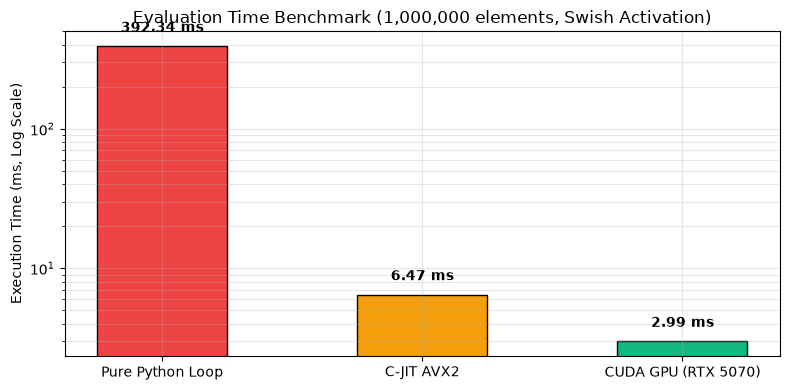

In [4]:
# Performance Visualization
modes = ['Pure Python Loop', 'C-JIT AVX2', 'CUDA GPU (RTX 5070)']
times_ms = [t_py_scaled * 1000, t_c * 1000, t_cuda * 1000]
colors = ['#ef4444', '#f59e0b', '#10b981']

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(modes, times_ms, color=colors, edgecolor='black', width=0.5)
ax.set_yscale('log')
ax.set_ylabel('Execution Time (ms, Log Scale)')
ax.set_title(f'Evaluation Time Benchmark ({N:,} elements, Swish Activation)')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h * 1.2, f'{h:.2f} ms', ha='center', va='bottom', fontweight='bold')
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()
